# Análisis científico final — modelo barotrópico con difusión

Modelo:
$
p=\omega\rho,\qquad Q=\alpha\rho^\beta,
$
$
3H^2=\rho+\alpha\rho^\beta=\rho F(\rho),
$
$
F(\rho)=1+\alpha\rho^{\beta-1},\qquad
D(\rho)=1+\alpha\beta\rho^{\beta-1},
$
$
\dot\rho=-\frac{3H(1+\omega)\rho}{D(\rho)},\qquad
\dot H=-\frac{1+\omega}{2}\rho.
$

## Objetivos

1. Reproducir los casos representativos B1–F4.
2. Construir un barrido sistemático en $((\alpha,\beta,\omega))$.
3. Generar mapas de comportamiento en slices de $(\omega)$.
4. Detectar fronteras numéricas entre regiones.
5. Contrastar la transición finito/infinito con la predicción asintótica $(\beta=2)$ en la rama phantom con $(\alpha>0)$.
6. Identificar Big Rip, Tipos II–IV, Little Rip, Little Sibling, de Sitter, turnaround/Big Crunch, rip dominado por difusión y comportamientos nuevos.


## 0. Preparación

Copia el archivo `parameter_space.py` entregado junto con este notebook a:

```text
src/parameter_space.py
```

El barrido usa checkpoints CSV y puede reanudarse si se interrumpe.


In [20]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    candidate = PROJECT_ROOT.parent
    if (candidate / "src").exists():
        PROJECT_ROOT = candidate
    else:
        raise FileNotFoundError(
            "No se encontró src/. Abre el notebook desde la raíz del proyecto "
            "o desde una subcarpeta directa."
        )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

OUTPUT_DIR = PROJECT_ROOT / "data" / "processed" / "barotropic_parameter_space"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("PROJECT_ROOT =", PROJECT_ROOT)
print("OUTPUT_DIR  =", OUTPUT_DIR)


PROJECT_ROOT = /Users/macbook/Usach/TesisxD/cosmo_singularities
OUTPUT_DIR  = /Users/macbook/Usach/TesisxD/cosmo_singularities/data/processed/barotropic_parameter_space


In [21]:
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import src.models as models_module
import src.singularities as singularities_module
import src.classifiers as classifiers_module
import src.barotropic_analysis as analysis_module
import src.parameter_space as parameter_space_module

importlib.reload(models_module)
importlib.reload(singularities_module)
importlib.reload(classifiers_module)
importlib.reload(analysis_module)
importlib.reload(parameter_space_module)

from src.models import BarotropicPowerDiffusionParams
from src.barotropic_analysis import analyze_parameter_catalog
from src.parameter_space import (
    analyze_parameter_grid,
    behavior_matrix,
    build_parameter_grid,
    compare_phantom_beta2_prediction,
    detect_behavior_boundaries,
    detect_finite_time_beta_transition,
    encode_behavior_matrix,
    summarize_transitions,
)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 200)
print("Importaciones completadas.")


Importaciones completadas.


## 1. Configuración del barrido

In [22]:
# Usa "pilot" primero. Cambia a "full" después de inspeccionar fronteras.
SCAN_MODE = "full"

if SCAN_MODE == "pilot":
    ALPHA_VALUES = np.linspace(-0.9, 3.0, 11)
    BETA_VALUES = np.linspace(-2.0, 3.0, 13)
    OMEGA_VALUES = np.array([-1.2, -1.0, -0.8, 0.0])
    ANALYSIS_KWARGS = {
        "t_end": 20.0,
        "n_points": 1600,
        "max_step": 0.01,
        "density_decades": 8,
        "boundary_tolerances": [1e-2, 1e-3, 1e-4, 1e-5, 1e-6],
        "collapse_rho_max_values": [1e2, 1e3, 1e4, 1e5, 1e6],
    }
elif SCAN_MODE == "full":
    ALPHA_VALUES = np.linspace(-0.9, 4.0, 25)
    BETA_VALUES = np.linspace(-2.0, 3.0, 31)
    OMEGA_VALUES = np.array([-1.4, -1.2, -1.05, -1.0, -0.95, -0.8, 0.0])
    ANALYSIS_KWARGS = {
        "t_end": 50.0,
        "n_points": 3000,
        "max_step": 0.005,
        "density_decades": 10,
        "boundary_tolerances": [1e-2, 1e-3, 1e-4, 1e-5, 1e-6, 1e-7],
        "collapse_rho_max_values": [1e2, 1e3, 1e4, 1e5, 1e6, 1e7],
    }
else:
    raise ValueError("SCAN_MODE debe ser 'pilot' o 'full'.")

print("SCAN_MODE =", SCAN_MODE)
print("N alpha   =", len(ALPHA_VALUES))
print("N beta    =", len(BETA_VALUES))
print("N omega   =", len(OMEGA_VALUES))
print("Puntos totales =", len(ALPHA_VALUES) * len(BETA_VALUES) * len(OMEGA_VALUES))


SCAN_MODE = full
N alpha   = 25
N beta    = 31
N omega   = 7
Puntos totales = 5425


## 2. Casos representativos B1–F4

In [23]:
REPRESENTATIVE_CASES = {
    "B1": BarotropicPowerDiffusionParams(omega=0.0, alpha=0.3, beta=1.0, rho0=1.0, a0=1.0, t0=0.0),
    "B2": BarotropicPowerDiffusionParams(omega=-1.0, alpha=0.3, beta=1.0, rho0=1.0, a0=1.0, t0=0.0),
    "B3": BarotropicPowerDiffusionParams(omega=-1.2, alpha=0.3, beta=1.0, rho0=1.0, a0=1.0, t0=0.0),
    "C1": BarotropicPowerDiffusionParams(omega=-1.2, alpha=0.3, beta=1.5, rho0=1.0, a0=1.0, t0=0.0),
    "C2": BarotropicPowerDiffusionParams(omega=-1.2, alpha=0.3, beta=2.0, rho0=1.0, a0=1.0, t0=0.0),
    "C3": BarotropicPowerDiffusionParams(omega=-1.2, alpha=0.3, beta=3.0, rho0=1.0, a0=1.0, t0=0.0),
    "C4": BarotropicPowerDiffusionParams(omega=-1.2, alpha=-0.3, beta=1.5, rho0=1.0, a0=1.0, t0=0.0),
    "D1": BarotropicPowerDiffusionParams(omega=0.0, alpha=0.3, beta=0.5, rho0=1.0, a0=1.0, t0=0.0),
    "D2": BarotropicPowerDiffusionParams(omega=-1.2, alpha=0.3, beta=0.5, rho0=1.0, a0=1.0, t0=0.0),
    "D3": BarotropicPowerDiffusionParams(omega=0.0, alpha=-0.5, beta=0.5, rho0=1.0, a0=1.0, t0=0.0),
    "E1": BarotropicPowerDiffusionParams(omega=0.0, alpha=0.3, beta=0.0, rho0=1.0, a0=1.0, t0=0.0),
    "E2": BarotropicPowerDiffusionParams(omega=0.0, alpha=-0.5, beta=0.0, rho0=1.0, a0=1.0, t0=0.0),
    "F1": BarotropicPowerDiffusionParams(omega=-1.2, alpha=0.25, beta=-1.0, rho0=1.0, a0=1.0, t0=0.0),
    "F2": BarotropicPowerDiffusionParams(omega=-1.2, alpha=4.0, beta=-1.0, rho0=1.0, a0=1.0, t0=0.0),
    "F3": BarotropicPowerDiffusionParams(omega=0.0, alpha=0.25, beta=-1.0, rho0=1.0, a0=1.0, t0=0.0),
    "F4": BarotropicPowerDiffusionParams(omega=0.0, alpha=-0.5, beta=-1.0, rho0=1.0, a0=1.0, t0=0.0),
}

representative_catalog = analyze_parameter_catalog(
    REPRESENTATIVE_CASES,
    **ANALYSIS_KWARGS,
)

columns = [
    "case_id", "omega", "alpha", "beta", "analysis_route", "standard_type",
    "behavior_label", "finite_time", "rho_limit", "p_limit", "a_limit",
    "H_limit", "Hdot_limit", "turnaround_detected", "confidence",
]
display(representative_catalog.summary[columns])
print("Errores:", representative_catalog.errors)


,case_id,omega,alpha,beta,analysis_route,standard_type,behavior_label,finite_time,rho_limit,p_limit,a_limit,H_limit,Hdot_limit,turnaround_detected,confidence
0,B1,0.0,0.30,1.0,density_limit,Non singular,regular_expansion,False,zero,zero,unknown,unknown,zero,False,0.85
1,B2,-1.0,0.30,1.0,stationary_density,Non singular,de_sitter,False,None,unknown,None,None,None,False,0.95
2,B3,-1.2,0.30,1.0,density_limit,Type I / Big Rip,type_i_big_rip,True,diverges,diverges,diverges,diverges,diverges,False,0.95
3,C1,-1.2,0.30,1.5,density_limit,Type I / Big Rip,type_i_big_rip,True,diverges,diverges,diverges,diverges,diverges,False,0.95
4,C2,-1.2,0.30,2.0,density_limit,Non singular,little rip,False,diverges,diverges,diverges,diverges,diverges,False,0.95
5,C3,-1.2,0.30,3.0,density_limit,Non singular,little rip,False,diverges,diverges,diverges,diverges,diverges,False,0.95
6,C4,-1.2,-0.30,1.5,boundary_D,Type IV,higher_derivative_boundary,True,finite,finite,finite,finite,finite,False,0.95
7,D1,0.0,0.30,0.5,density_limit,Non singular,regular_expansion,False,zero,zero,diverges,unknown,zero,False,0.90
8,D2,-1.2,0.30,0.5,density_limit,Type I / Big Rip,type_i_big_rip,True,diverges,diverges,diverges,diverges,diverges,False,0.95
9,D3,0.0,-0.50,0.5,boundary_F,None,turnaround_to_big_crunch,True,diverges,zero,zero,diverges,diverges,True,0.95


Errores: {}


## 3. Gráficos de soluciones representativas

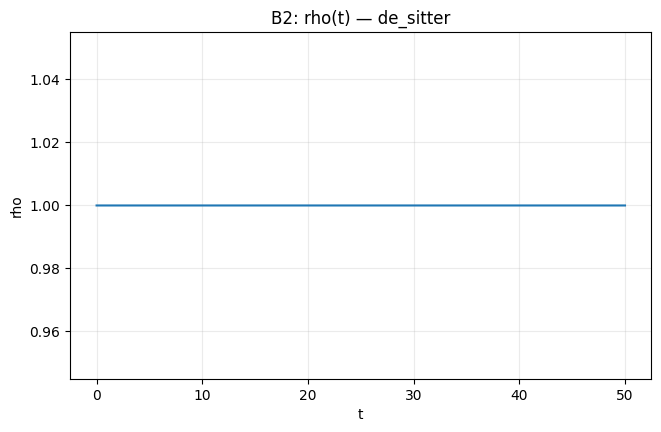

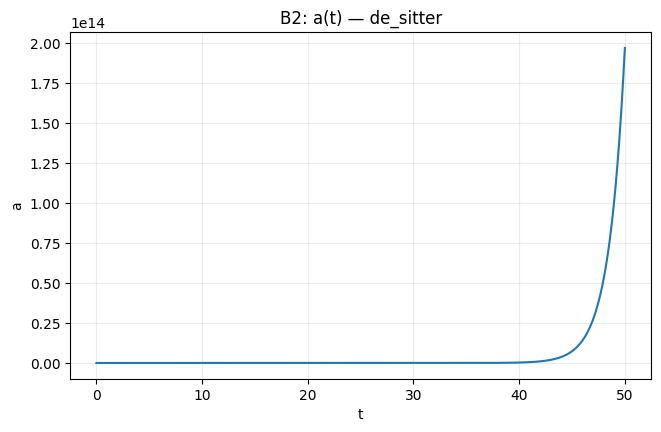

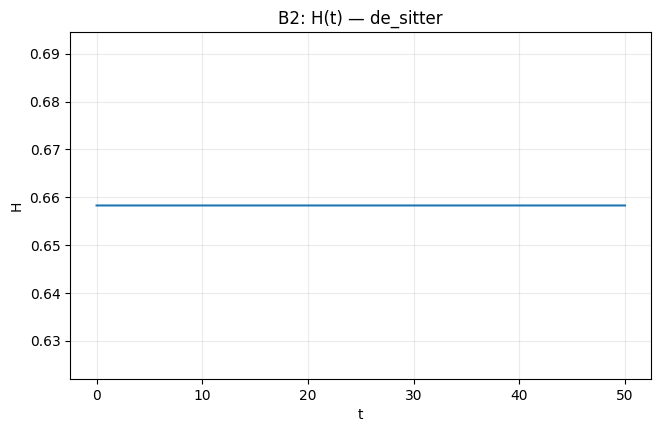

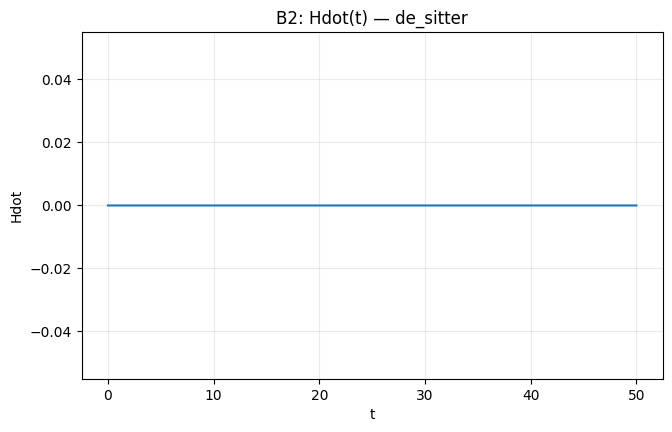

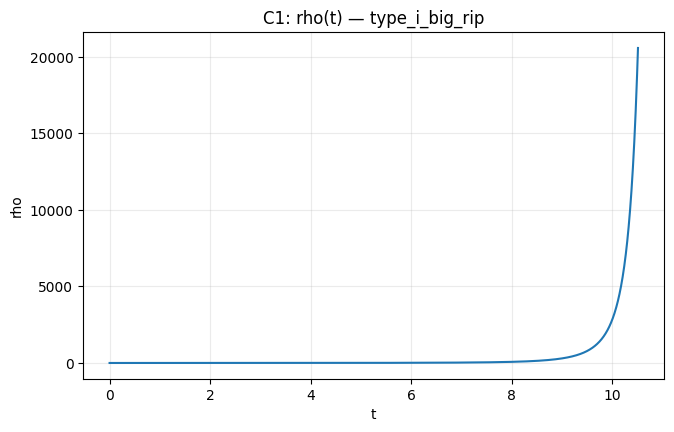

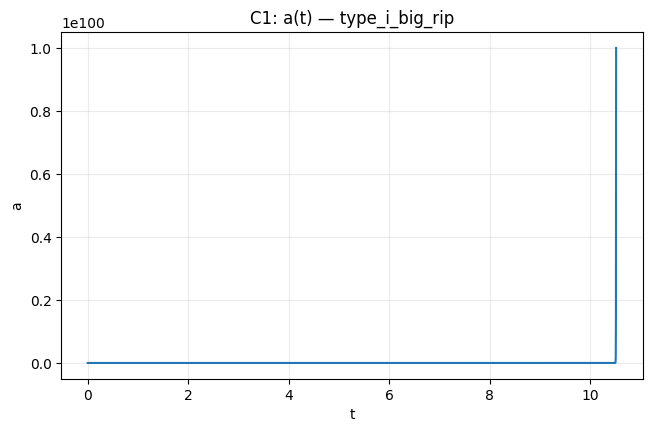

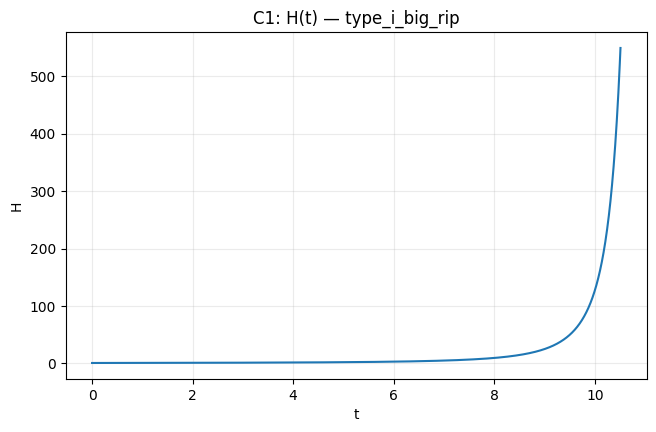

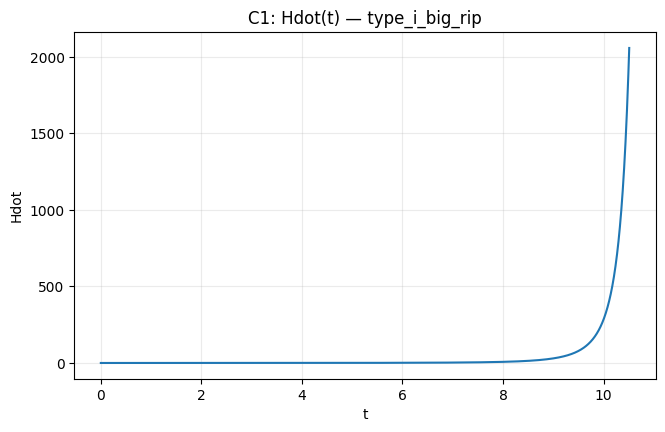

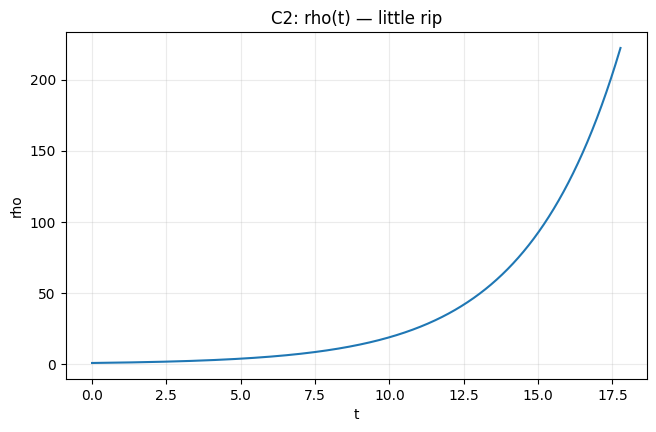

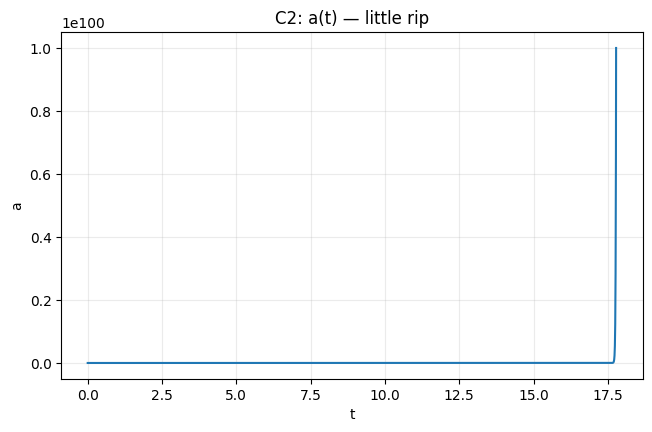

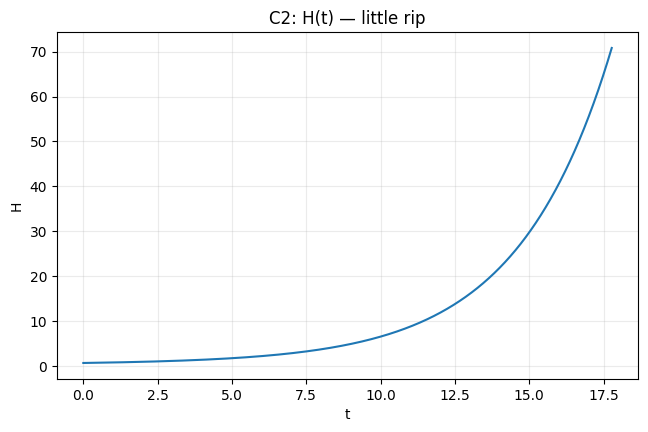

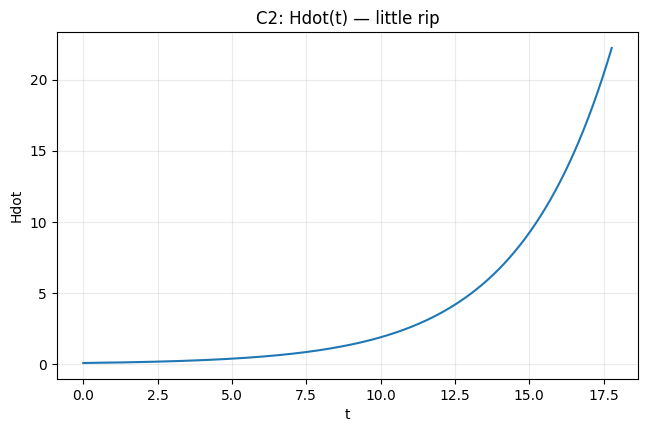

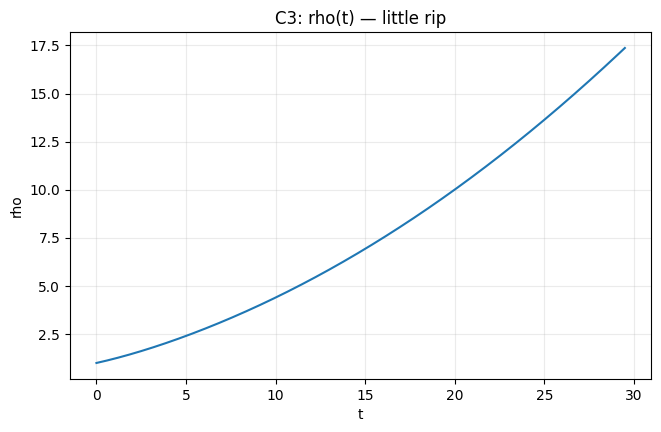

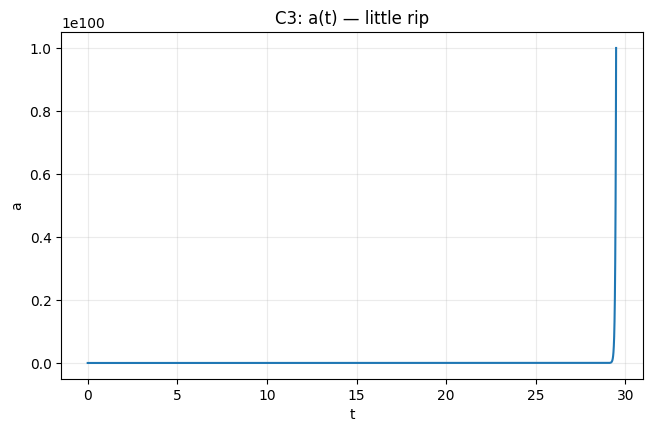

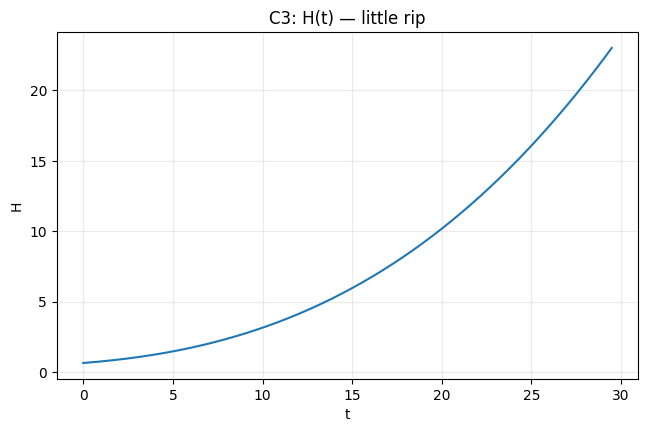

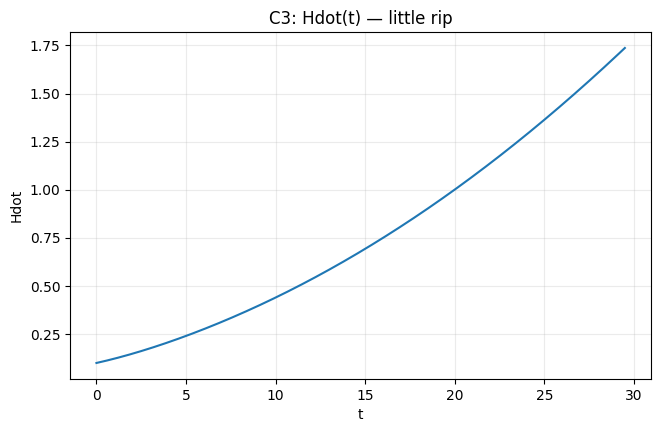

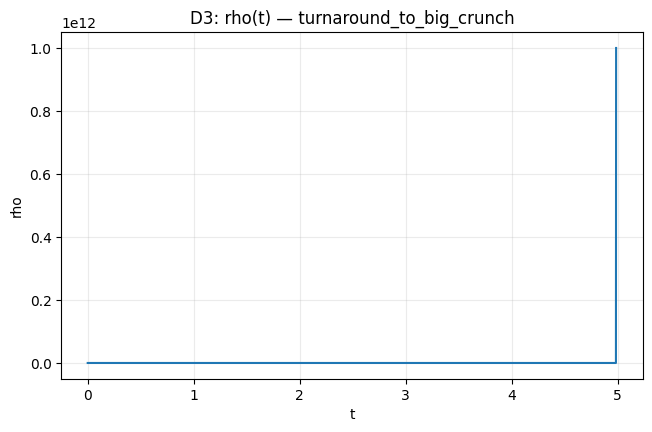

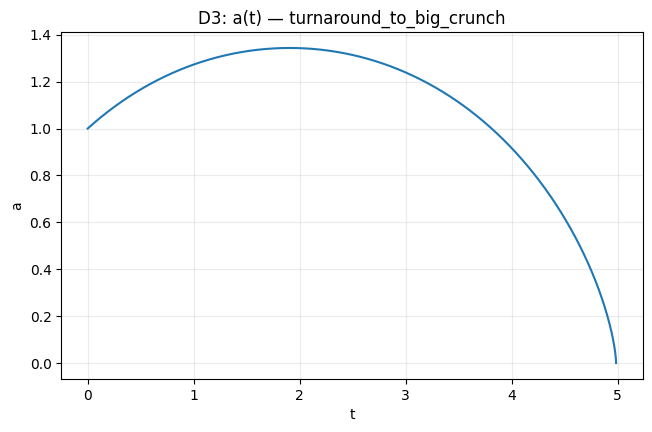

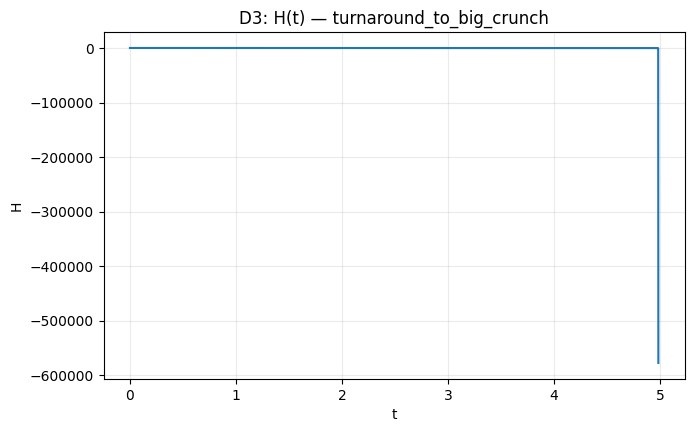

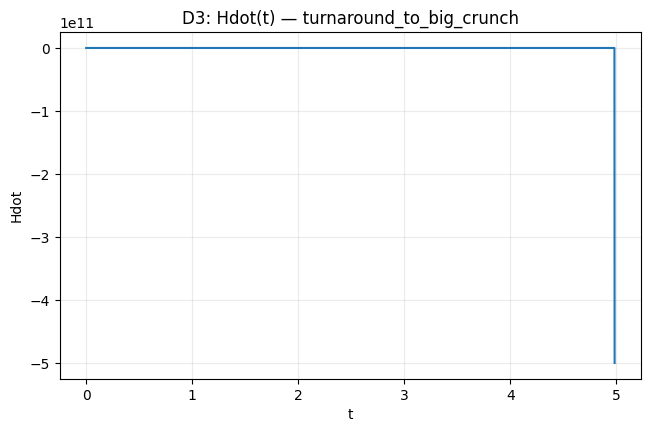

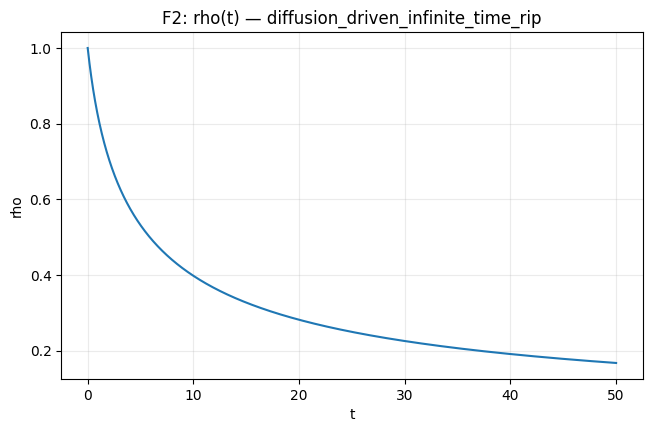

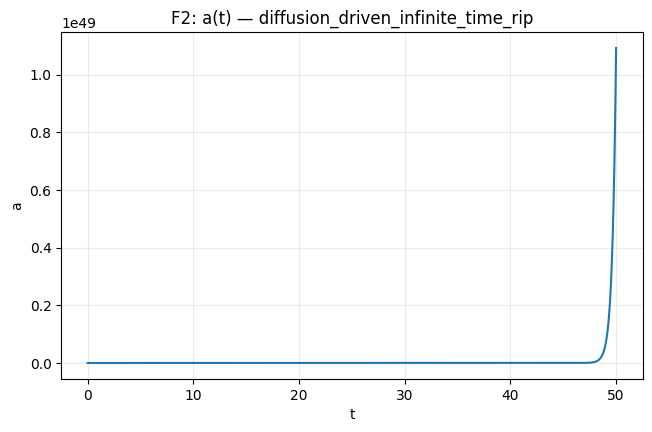

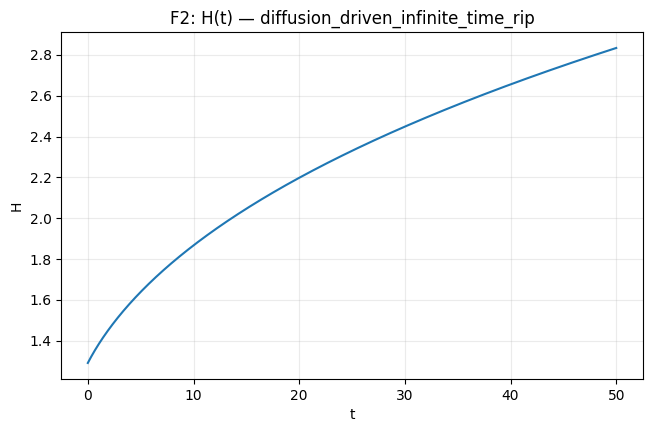

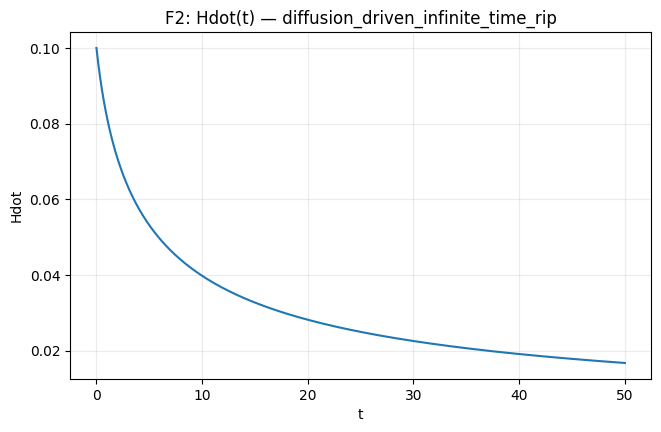

In [24]:
def plot_case_variable(analysis, variable):
    background = (
        analysis.signed_background
        if analysis.signed_background is not None
        else analysis.background
    )
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.plot(background["t"], background[variable])
    ax.set_xlabel("t")
    ax.set_ylabel(variable)
    ax.set_title(
        f"{analysis.case_id}: {variable}(t) — "
        f"{analysis.classification.behavior_label}"
    )
    ax.grid(True, alpha=0.25)
    plt.show()

for case_id in ["B2", "C1", "C2", "C3", "D3", "F2"]:
    if case_id not in representative_catalog.analyses:
        continue
    analysis = representative_catalog.analyses[case_id]
    for variable in ["rho", "a", "H", "Hdot"]:
        plot_case_variable(analysis, variable)


## 4. Construcción de la grilla

Con $(\rho_0=1)$:
$
F_0=1+\alpha,\qquad D_0=1+\alpha\beta.
$
Los puntos con $(F_0\le 0)$ o que comienzan numéricamente sobre $(D_0=0)$ se conservan como región excluida del dominio inicial.


In [25]:
parameter_grid = build_parameter_grid(
    alpha_values=ALPHA_VALUES,
    beta_values=BETA_VALUES,
    omega_values=OMEGA_VALUES,
    rho0=1.0,
    a0=1.0,
    t0=0.0,
)

display(parameter_grid.head())
print("Puntos válidos:", int(parameter_grid["valid_initial_domain"].sum()))
print("Puntos excluidos:", int((~parameter_grid["valid_initial_domain"]).sum()))


,point_id,omega,alpha,beta,rho0,a0,t0,F0,D0,valid_initial_domain,invalid_reason
0,0,-1.4,-0.900000,-2.0,1.0,1.0,0.0,0.100000,2.800000,True,
1,1,-1.4,-0.695833,-2.0,1.0,1.0,0.0,0.304167,2.391667,True,
2,2,-1.4,-0.491667,-2.0,1.0,1.0,0.0,0.508333,1.983333,True,
3,3,-1.4,-0.287500,-2.0,1.0,1.0,0.0,0.712500,1.575000,True,
4,4,-1.4,-0.083333,-2.0,1.0,1.0,0.0,0.916667,1.166667,True,


Puntos válidos: 5425
Puntos excluidos: 0


## 5. Barrido sistemático con checkpoint

Cada slice de \(\omega\) se guarda por separado. Si se interrumpe, vuelve a ejecutar la celda con `resume=True`.


In [26]:
RUN_PARAMETER_SCAN = True
slice_results = []

if RUN_PARAMETER_SCAN:
    for omega in OMEGA_VALUES:
        omega_grid = parameter_grid[
            np.isclose(parameter_grid["omega"], omega, atol=1e-12, rtol=0.0)
        ].copy()

        omega_tag = (
            f"{omega:+.3f}"
            .replace("+", "p")
            .replace("-", "m")
            .replace(".", "d")
        )
        checkpoint = OUTPUT_DIR / f"parameter_scan_{SCAN_MODE}_omega_{omega_tag}.csv"

        print("=" * 70)
        print("omega =", omega)
        print("checkpoint =", checkpoint)

        result = analyze_parameter_grid(
            omega_grid,
            analysis_kwargs=ANALYSIS_KWARGS,
            checkpoint_path=checkpoint,
            resume=True,
            checkpoint_every=20,
            verbose=True,
        )
        slice_results.append(result)

    parameter_results = pd.concat(slice_results, ignore_index=True)
    combined_path = OUTPUT_DIR / f"parameter_scan_{SCAN_MODE}_combined.csv"
    parameter_results.to_csv(combined_path, index=False)
    print("Resultado combinado:", combined_path)
else:
    combined_path = OUTPUT_DIR / f"parameter_scan_{SCAN_MODE}_combined.csv"
    parameter_results = pd.read_csv(combined_path)

parameter_results.shape


omega = -1.4
checkpoint = /Users/macbook/Usach/TesisxD/cosmo_singularities/data/processed/barotropic_parameter_space/parameter_scan_full_omega_m1d400.csv
Puntos almacenados: 50 / 775
Puntos almacenados: 100 / 775
Puntos almacenados: 150 / 775
Puntos almacenados: 200 / 775
Puntos almacenados: 250 / 775
Puntos almacenados: 300 / 775
Puntos almacenados: 350 / 775
Puntos almacenados: 400 / 775
Puntos almacenados: 450 / 775
Puntos almacenados: 500 / 775
Puntos almacenados: 550 / 775
Puntos almacenados: 600 / 775
Puntos almacenados: 650 / 775
Puntos almacenados: 700 / 775
Puntos almacenados: 750 / 775
omega = -1.2
checkpoint = /Users/macbook/Usach/TesisxD/cosmo_singularities/data/processed/barotropic_parameter_space/parameter_scan_full_omega_m1d200.csv
Puntos almacenados: 50 / 775
Puntos almacenados: 100 / 775
Puntos almacenados: 150 / 775
Puntos almacenados: 200 / 775
Puntos almacenados: 250 / 775
Puntos almacenados: 300 / 775
Puntos almacenados: 350 / 775
Puntos almacenados: 400 / 775
Punt

/var/folders/7v/mpqjvkxx00lf3_k_1wpn9jsw0000gn/T/ipykernel_2554/2325412955.py:32: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  parameter_results = pd.concat(slice_results, ignore_index=True)


(5425, 37)

## 6. Control de calidad

In [27]:
quality_summary = (
    parameter_results.groupby(["omega", "status"], dropna=False)
    .size().rename("count").reset_index()
)
display(quality_summary)

error_rows = parameter_results[parameter_results["behavior_label"] == "analysis_error"]
print("Errores numéricos:", len(error_rows))
if len(error_rows) > 0:
    display(error_rows[["omega", "alpha", "beta", "error"]].head(50))


,omega,status,count
0,-1.40,new_behavior_candidate,133
1,-1.40,provisional,28
2,-1.40,robust,614
3,-1.20,new_behavior_candidate,131
4,-1.20,provisional,28
5,-1.20,robust,616
6,-1.05,new_behavior_candidate,130
7,-1.05,provisional,28
8,-1.05,robust,617
9,-1.00,robust,775


Errores numéricos: 0


## 7. Distribución de comportamientos

In [28]:
behavior_counts = (
    parameter_results.groupby(["omega", "behavior_label"], dropna=False)
    .size().rename("count").reset_index()
    .sort_values(["omega", "count"], ascending=[True, False])
)
display(behavior_counts)


,omega,behavior_label,count
5,-1.40,type_i_big_rip,414
3,-1.40,little rip,140
0,-1.40,diffusion_driven_infinite_time_rip,130
2,-1.40,higher_derivative_boundary,60
4,-1.40,regular_expansion,28
1,-1.40,finite_time_divergence,3
11,-1.20,type_i_big_rip,416
9,-1.20,little rip,140
6,-1.20,diffusion_driven_infinite_time_rip,130
8,-1.20,higher_derivative_boundary,60


## 8. Mapas de comportamiento en el plano $(\alpha,\beta)$

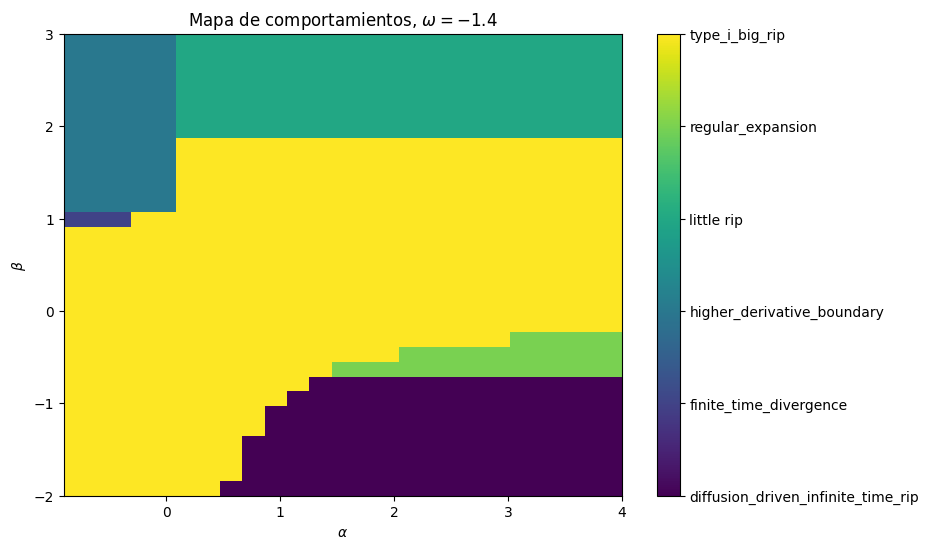

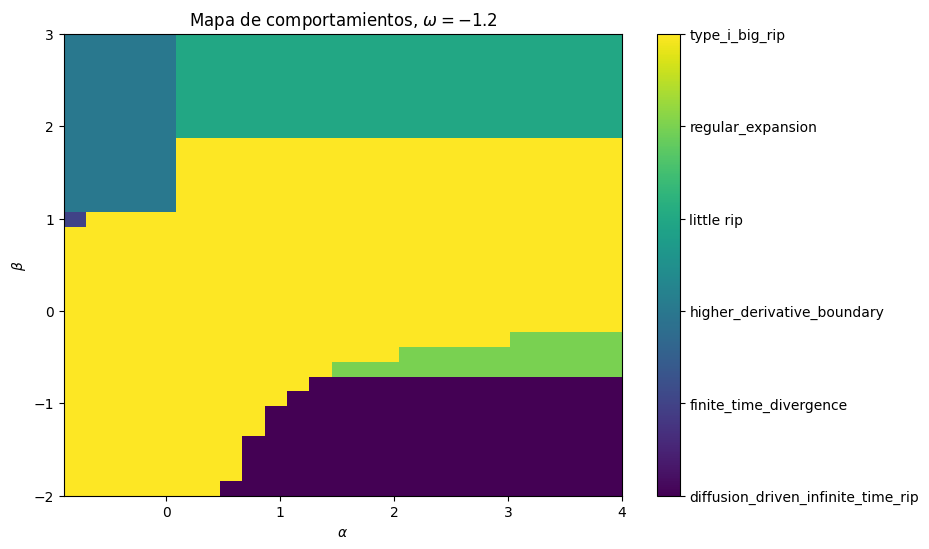

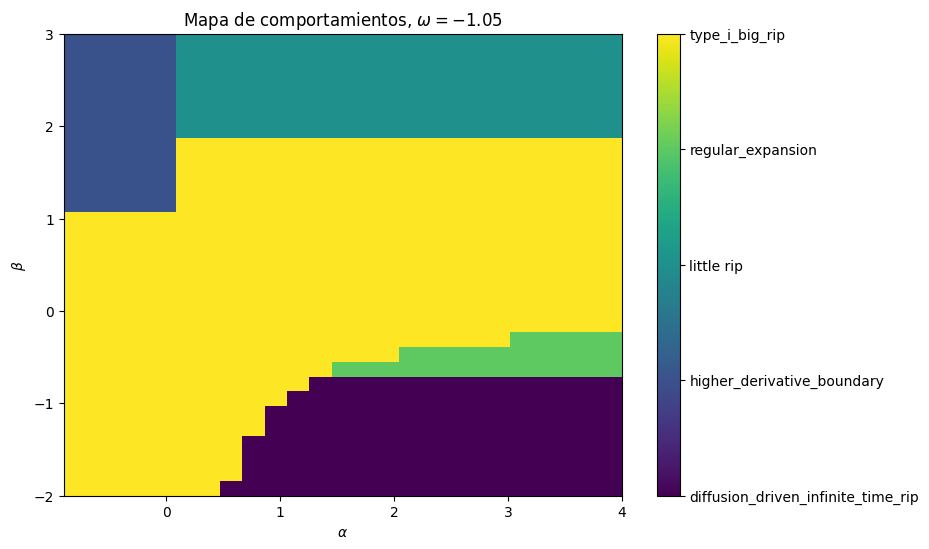

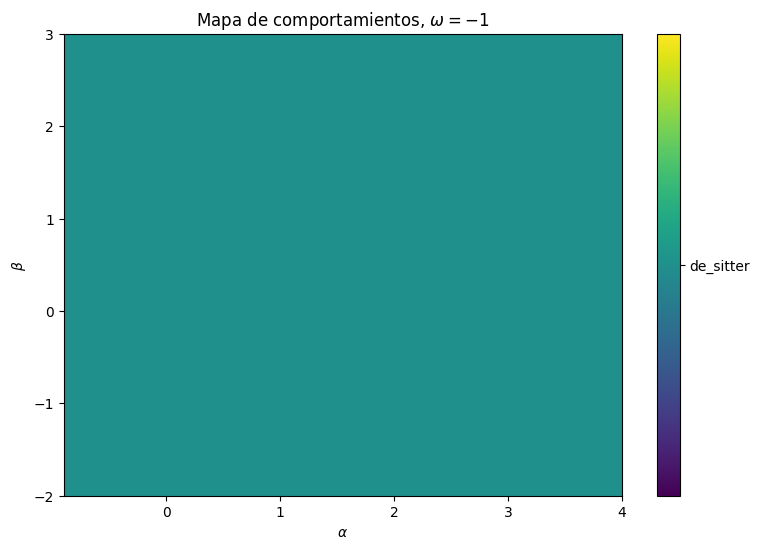

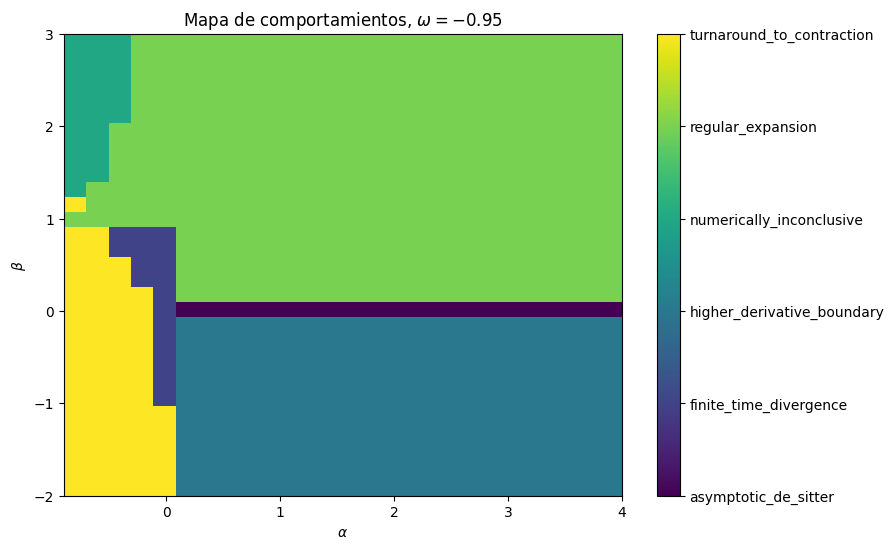

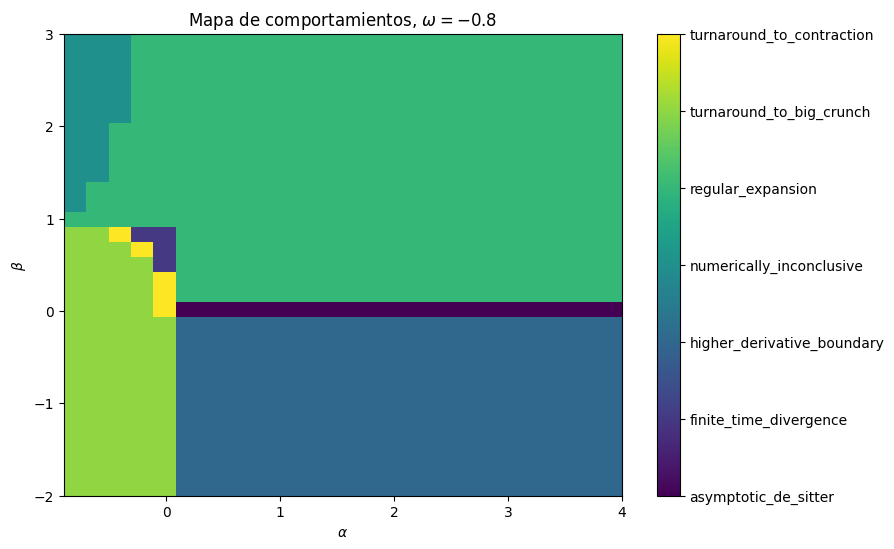

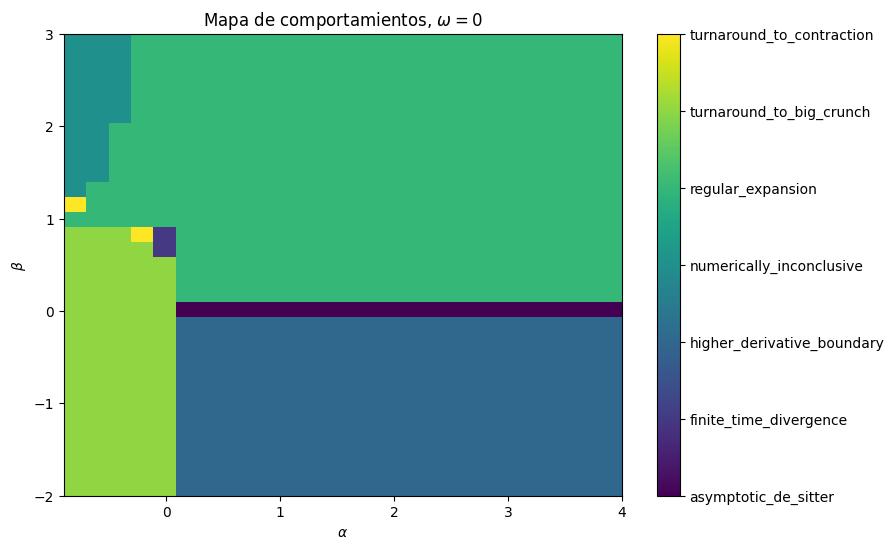

In [29]:
def plot_behavior_map(results, omega):
    matrix = behavior_matrix(results, omega)
    encoded, codebook = encode_behavior_matrix(matrix)
    alphas = matrix.columns.to_numpy(dtype=float)
    betas = matrix.index.to_numpy(dtype=float)

    fig, ax = plt.subplots(figsize=(9.0, 6.0))
    image = ax.imshow(
        encoded,
        origin="lower",
        aspect="auto",
        extent=[alphas.min(), alphas.max(), betas.min(), betas.max()],
        interpolation="nearest",
    )
    ax.set_xlabel(r"$\alpha$")
    ax.set_ylabel(r"$\beta$")
    ax.set_title(rf"Mapa de comportamientos, $\omega={omega:g}$")

    colorbar = fig.colorbar(image, ax=ax)
    ticks = list(codebook.keys())
    colorbar.set_ticks(ticks)
    colorbar.set_ticklabels([codebook[tick] for tick in ticks])
    plt.show()

for omega in OMEGA_VALUES:
    plot_behavior_map(parameter_results, omega)


## 9. Fronteras numéricas entre regiones

In [30]:
all_boundaries = []
for omega in OMEGA_VALUES:
    boundaries = detect_behavior_boundaries(
        parameter_results,
        omega,
        include_invalid=False,
    )
    if not boundaries.empty:
        all_boundaries.append(boundaries)
    print("omega =", omega)
    display(summarize_transitions(boundaries))

behavior_boundaries = (
    pd.concat(all_boundaries, ignore_index=True)
    if all_boundaries
    else pd.DataFrame()
)

display(behavior_boundaries.head())


omega = -1.4


,behavior_1,behavior_2,count
0,little rip,type_i_big_rip,20
1,regular_expansion,type_i_big_rip,16
2,diffusion_driven_infinite_time_rip,type_i_big_rip,13
3,diffusion_driven_infinite_time_rip,regular_expansion,13
4,higher_derivative_boundary,type_i_big_rip,7
5,higher_derivative_boundary,little rip,7
6,finite_time_divergence,type_i_big_rip,4
7,finite_time_divergence,higher_derivative_boundary,3


omega = -1.2


,behavior_1,behavior_2,count
0,little rip,type_i_big_rip,20
1,regular_expansion,type_i_big_rip,16
2,diffusion_driven_infinite_time_rip,type_i_big_rip,13
3,diffusion_driven_infinite_time_rip,regular_expansion,13
4,higher_derivative_boundary,type_i_big_rip,9
5,higher_derivative_boundary,little rip,7
6,finite_time_divergence,type_i_big_rip,2
7,finite_time_divergence,higher_derivative_boundary,1


omega = -1.05


,behavior_1,behavior_2,count
0,little rip,type_i_big_rip,20
1,regular_expansion,type_i_big_rip,16
2,diffusion_driven_infinite_time_rip,type_i_big_rip,13
3,diffusion_driven_infinite_time_rip,regular_expansion,13
4,higher_derivative_boundary,type_i_big_rip,10
5,higher_derivative_boundary,little rip,7


... (5 outputs left out)

,behavior_1,behavior_2,count
0,asymptotic_de_sitter,higher_derivative_boundary,20
1,asymptotic_de_sitter,regular_expansion,20
2,numerically_inconclusive,regular_expansion,15
3,higher_derivative_boundary,turnaround_to_big_crunch,12
4,turnaround_to_big_crunch,turnaround_to_contraction,8
5,finite_time_divergence,regular_expansion,5
6,finite_time_divergence,turnaround_to_contraction,4
7,regular_expansion,turnaround_to_contraction,3
8,regular_expansion,turnaround_to_big_crunch,2
9,asymptotic_de_sitter,turnaround_to_contraction,1


omega = 0.0


,behavior_1,behavior_2,count
0,asymptotic_de_sitter,higher_derivative_boundary,20
1,asymptotic_de_sitter,regular_expansion,20
2,numerically_inconclusive,regular_expansion,13
3,higher_derivative_boundary,turnaround_to_big_crunch,12
4,regular_expansion,turnaround_to_big_crunch,6
5,finite_time_divergence,regular_expansion,3
6,regular_expansion,turnaround_to_contraction,3
7,finite_time_divergence,turnaround_to_big_crunch,2
8,turnaround_to_big_crunch,turnaround_to_contraction,2
9,asymptotic_de_sitter,turnaround_to_big_crunch,1


,omega,orientation,alpha_mid,beta_mid,label_1,label_2
0,-1.4,alpha,0.427083,-2.000000,type_i_big_rip,diffusion_driven_infinite_time_rip
1,-1.4,alpha,0.631250,-1.833333,type_i_big_rip,diffusion_driven_infinite_time_rip
2,-1.4,alpha,0.631250,-1.666667,type_i_big_rip,diffusion_driven_infinite_time_rip
3,-1.4,alpha,0.631250,-1.500000,type_i_big_rip,diffusion_driven_infinite_time_rip
4,-1.4,alpha,0.835417,-1.333333,type_i_big_rip,diffusion_driven_infinite_time_rip


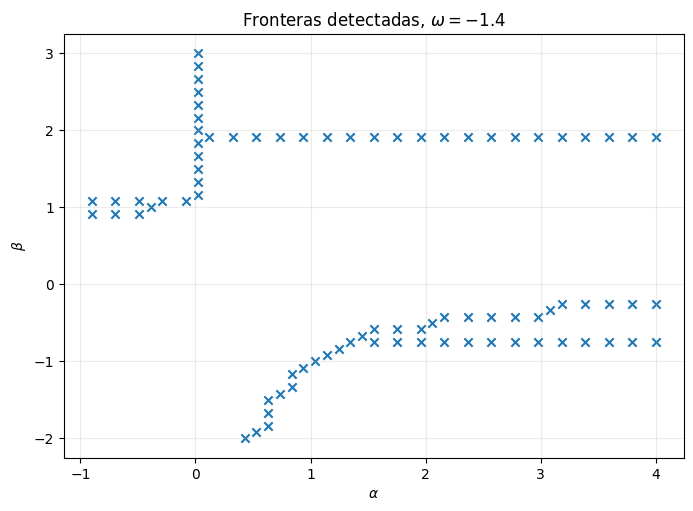

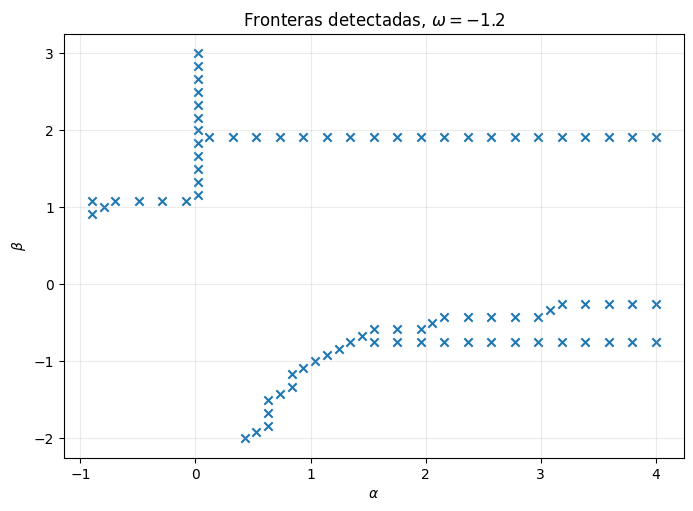

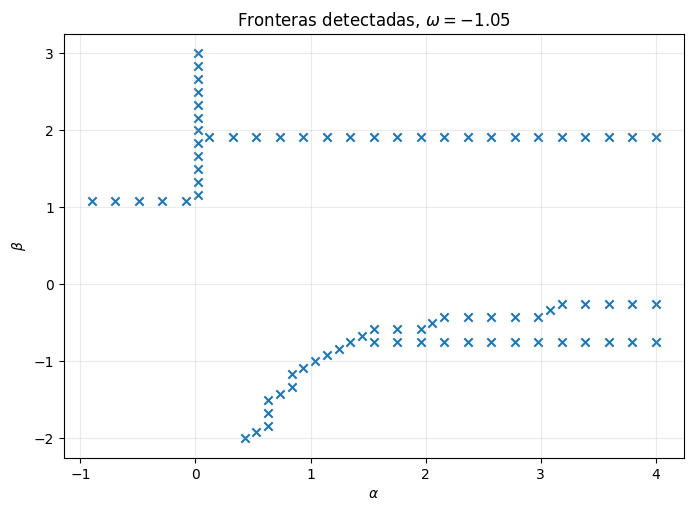

No se detectaron fronteras para omega = -1.0


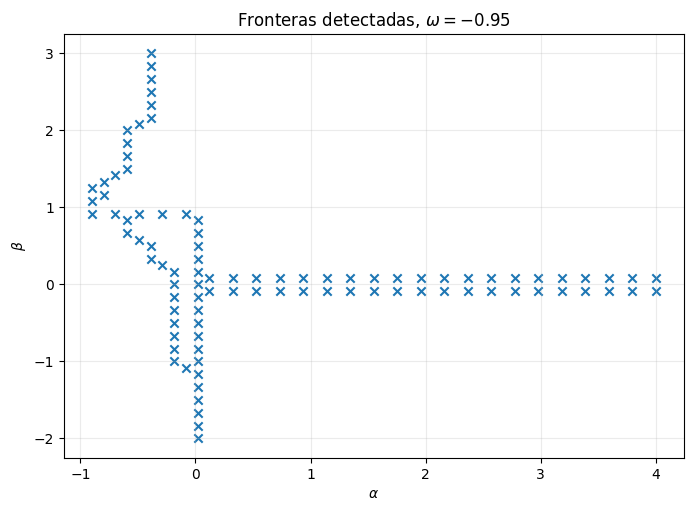

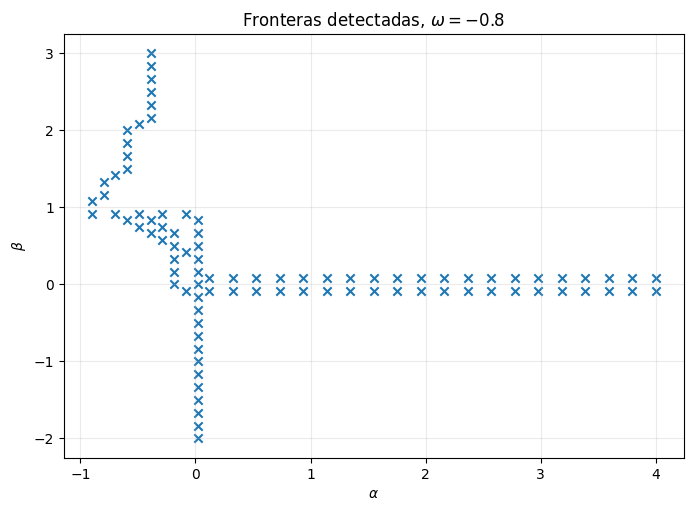

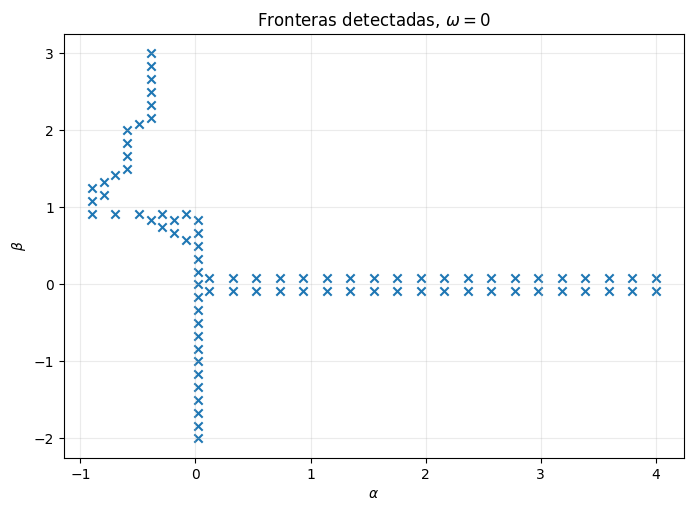

In [31]:
def plot_detected_boundaries(boundaries, omega):
    if boundaries.empty:
        return
    selected = boundaries[
        np.isclose(boundaries["omega"], omega, atol=1e-12, rtol=0.0)
    ].copy()
    if selected.empty:
        print("No se detectaron fronteras para omega =", omega)
        return

    fig, ax = plt.subplots(figsize=(8.0, 5.5))
    ax.scatter(selected["alpha_mid"], selected["beta_mid"], marker="x")
    ax.set_xlabel(r"$\alpha$")
    ax.set_ylabel(r"$\beta$")
    ax.set_title(rf"Fronteras detectadas, $\omega={omega:g}$")
    ax.grid(True, alpha=0.25)
    plt.show()

for omega in OMEGA_VALUES:
    plot_detected_boundaries(behavior_boundaries, omega)


## 10. Frontera asintótica $(\beta=2)$ para $(\alpha>0)$, $(\omega<-1)$

En alta densidad y para $(\beta>1)$:
$
F\sim\alpha\rho^{\beta-1},\qquad
D\sim\alpha\beta\rho^{\beta-1},
$
$
H\sim\sqrt{\frac{\alpha}{3}}\rho^{\beta/2},
$
$
\dot\rho\sim
\frac{\sqrt{3}}{\beta\sqrt{\alpha}}|1+\omega|
\rho^{2-\beta/2}.
$
Entonces
$
t_s-t\propto\int_\rho^\infty x^{-(2-\beta/2)}\,dx.
$
La integral converge para $(\beta<2)$, es marginalmente logarítmica para $(\beta=2)$, y diverge para $(\beta>2)$.


In [33]:
beta2_comparison = compare_phantom_beta2_prediction(parameter_results)
if beta2_comparison.empty:
    print("No hay puntos comparables en la malla actual.")
else:
    agreement = float(beta2_comparison["finite_time_agreement"].mean())
    print("Puntos comparados:", len(beta2_comparison))
    print("Fracción de acuerdo con beta=2:", agreement)
    disagreements = beta2_comparison[~beta2_comparison["finite_time_agreement"]]
    print("Desacuerdos:", len(disagreements))
    if len(disagreements) > 0:
        display(disagreements[[
            "omega", "alpha", "beta", "behavior_label", "finite_time",
            "asymptotic_finite_time_prediction", "confidence",
        ]])


Puntos comparados: 1386
Fracción de acuerdo con beta=2: 1.0
Desacuerdos: 0


omega = -1.4


,omega,alpha,beta_left,beta_right,beta_mid
0,-1.4,0.120833,1.833333,2.0,1.916667
1,-1.4,0.325000,1.833333,2.0,1.916667
2,-1.4,0.529167,1.833333,2.0,1.916667
3,-1.4,0.733333,1.833333,2.0,1.916667
4,-1.4,0.937500,1.833333,2.0,1.916667
5,-1.4,1.141667,1.833333,2.0,1.916667
6,-1.4,1.345833,1.833333,2.0,1.916667
7,-1.4,1.550000,1.833333,2.0,1.916667
8,-1.4,1.754167,1.833333,2.0,1.916667
9,-1.4,1.958333,1.833333,2.0,1.916667


beta_mid medio = 1.916666666666666
omega = -1.2


,omega,alpha,beta_left,beta_right,beta_mid
0,-1.2,0.120833,1.833333,2.0,1.916667
1,-1.2,0.325000,1.833333,2.0,1.916667
2,-1.2,0.529167,1.833333,2.0,1.916667
3,-1.2,0.733333,1.833333,2.0,1.916667
4,-1.2,0.937500,1.833333,2.0,1.916667
5,-1.2,1.141667,1.833333,2.0,1.916667
6,-1.2,1.345833,1.833333,2.0,1.916667
7,-1.2,1.550000,1.833333,2.0,1.916667
8,-1.2,1.754167,1.833333,2.0,1.916667
9,-1.2,1.958333,1.833333,2.0,1.916667


beta_mid medio = 1.916666666666666
omega = -1.05


,omega,alpha,beta_left,beta_right,beta_mid
0,-1.05,0.120833,1.833333,2.0,1.916667
1,-1.05,0.325000,1.833333,2.0,1.916667
2,-1.05,0.529167,1.833333,2.0,1.916667
3,-1.05,0.733333,1.833333,2.0,1.916667
4,-1.05,0.937500,1.833333,2.0,1.916667
5,-1.05,1.141667,1.833333,2.0,1.916667
6,-1.05,1.345833,1.833333,2.0,1.916667
7,-1.05,1.550000,1.833333,2.0,1.916667
8,-1.05,1.754167,1.833333,2.0,1.916667
9,-1.05,1.958333,1.833333,2.0,1.916667


beta_mid medio = 1.916666666666666


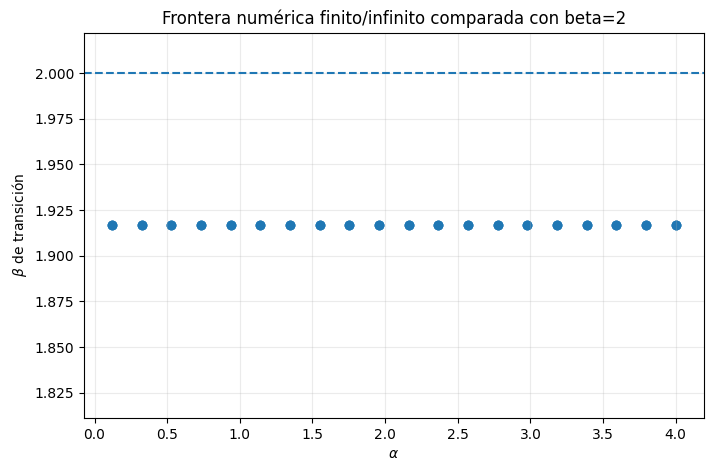

In [34]:
finite_time_boundaries = []
for omega in OMEGA_VALUES:
    if omega >= -1.0:
        continue
    transitions = detect_finite_time_beta_transition(parameter_results, omega)
    if not transitions.empty:
        finite_time_boundaries.append(transitions)
        print("omega =", omega)
        display(transitions)
        print("beta_mid medio =", transitions["beta_mid"].mean())

beta_transition_table = (
    pd.concat(finite_time_boundaries, ignore_index=True)
    if finite_time_boundaries
    else pd.DataFrame()
)

if not beta_transition_table.empty:
    fig, ax = plt.subplots(figsize=(8.0, 5.0))
    ax.scatter(beta_transition_table["alpha"], beta_transition_table["beta_mid"])
    ax.axhline(2.0, linestyle="--")
    ax.set_xlabel(r"$\alpha$")
    ax.set_ylabel(r"$\beta$ de transición")
    ax.set_title("Frontera numérica finito/infinito comparada con beta=2")
    ax.grid(True, alpha=0.25)
    plt.show()


## 11. Tipo II y Little Sibling: restricciones estructurales

Como $(p=\omega\rho)$ con $(\omega)$ constante y finito, una densidad finita implica presión finita. Por ello, una Tipo II estándar no puede generarse dentro de estas hipótesis.

Además,
$
\dot H=-\frac{1+\omega}{2}\rho.
$
Si un Little Sibling exige $(\rho\to\infty)$ y $(\dot H\to C\neq0)$, la relación anterior lo excluye para $(\omega\neq-1)$; para $(\omega=-1)$, $(\dot H=0)$. El clasificador mantiene ambas categorías para no imponer la conclusión antes de analizar los datos.


In [35]:
labels_present = sorted(parameter_results["behavior_label"].dropna().unique())
print("Comportamientos presentes:")
for label in labels_present:
    print(" -", label)

for target in ["type_ii_sudden", "little_sibling_of_the_big_rip"]:
    print(target, ":", int((parameter_results["behavior_label"] == target).sum()))


Comportamientos presentes:
 - asymptotic_de_sitter
 - de_sitter
 - diffusion_driven_infinite_time_rip
 - finite_time_divergence
 - higher_derivative_boundary
 - little rip
 - numerically_inconclusive
 - regular_expansion
 - turnaround_to_big_crunch
 - turnaround_to_contraction
 - type_i_big_rip
type_ii_sudden : 0
little_sibling_of_the_big_rip : 0


## 12. Región $(\alpha<0)$: fronteras de Friedmann y turnaround

Para $(\alpha<0)$, cuando existe una raíz física,
$
\rho_F=\left(-\frac{1}{\alpha}\right)^{1/(\beta-1)}.
$
Si esta raíz se encuentra en la dirección futura de $(\rho)$, la rama expansiva llega a $(H=0)$. La solución signada decide si sigue una contracción y, eventualmente, un Big Crunch.


In [36]:
negative_alpha_summary = (
    parameter_results[
        (parameter_results["alpha"] < 0.0)
        & parameter_results["valid_initial_domain"]
    ]
    .groupby(["omega", "analysis_route", "behavior_label"], dropna=False)
    .size().rename("count").reset_index()
    .sort_values(["omega", "count"], ascending=[True, False])
)
display(negative_alpha_summary)


,omega,analysis_route,behavior_label,count
2,-1.40,density_limit,type_i_big_rip,92
0,-1.40,boundary_D,higher_derivative_boundary,60
1,-1.40,density_limit,finite_time_divergence,3
5,-1.20,density_limit,type_i_big_rip,94
3,-1.20,boundary_D,higher_derivative_boundary,60
4,-1.20,density_limit,finite_time_divergence,1
7,-1.05,density_limit,type_i_big_rip,95
6,-1.05,boundary_D,higher_derivative_boundary,60
8,-1.00,stationary_density,de_sitter,155
11,-0.95,boundary_F,turnaround_to_contraction,73


## 13. Región $(\alpha>0,\beta<0,\omega<-1)$: rip dominado por difusión

Para $(\rho\to0)$, $(\alpha>0)$ y $(\beta<0)$:
$
H^2\simeq\frac{\alpha}{3}\rho^\beta\to\infty,
$
mientras
$
\dot H=-\frac{1+\omega}{2}\rho\to0.
$
Este patrón es distinto de un Little Rip convencional porque la densidad tiende a cero.


In [37]:
diffusion_region = parameter_results[
    (parameter_results["alpha"] > 0.0)
    & (parameter_results["beta"] < 0.0)
    & (parameter_results["omega"] < -1.0)
].copy()

display(diffusion_region[[
    "omega", "alpha", "beta", "behavior_label", "time_limit",
    "rho_limit", "a_limit", "H_limit", "Hdot_limit", "confidence",
]].sort_values(["omega", "beta", "alpha"]))


,omega,alpha,beta,behavior_label,time_limit,rho_limit,a_limit,H_limit,Hdot_limit,confidence
5,-1.40,0.120833,-2.000000,type_i_big_rip,finite,diverges,diverges,diverges,diverges,0.95
6,-1.40,0.325000,-2.000000,type_i_big_rip,finite,diverges,diverges,diverges,diverges,0.95
7,-1.40,0.529167,-2.000000,diffusion_driven_infinite_time_rip,infinite,zero,diverges,diverges,zero,0.95
8,-1.40,0.733333,-2.000000,diffusion_driven_infinite_time_rip,infinite,zero,diverges,diverges,zero,0.95
9,-1.40,0.937500,-2.000000,diffusion_driven_infinite_time_rip,infinite,zero,diverges,diverges,zero,0.95
...,...,...,...,...,...,...,...,...,...,...
1845,-1.05,3.183333,-0.166667,type_i_big_rip,finite,diverges,diverges,diverges,diverges,0.95
1846,-1.05,3.387500,-0.166667,type_i_big_rip,finite,diverges,diverges,diverges,diverges,0.95
1847,-1.05,3.591667,-0.166667,type_i_big_rip,finite,diverges,diverges,diverges,diverges,0.95
1848,-1.05,3.795833,-0.166667,type_i_big_rip,finite,diverges,diverges,diverges,diverges,0.95


## 14. Candidatos a comportamiento nuevo o inconcluso

In [38]:
candidate_labels = [
    "new_behavior_candidate",
    "infinite_time_divergence",
    "analysis_error",
]
new_candidates = parameter_results[
    parameter_results["behavior_label"].isin(candidate_labels)
].copy()

display(new_candidates[[
    "omega", "alpha", "beta", "behavior_label", "status", "finite_time",
    "rho_limit", "p_limit", "a_limit", "H_limit", "Hdot_limit",
    "rho_dot_limit", "Hddot_limit", "confidence", "error",
]].sort_values(["omega", "beta", "alpha"]))


,omega,alpha,beta,behavior_label,status,finite_time,rho_limit,p_limit,a_limit,H_limit,Hdot_limit,rho_dot_limit,Hddot_limit,confidence,error


## 15. Tabla científica y exportación

In [39]:
scientific_columns = [
    "omega", "alpha", "beta", "rho_F", "rho_D", "analysis_route",
    "standard_type", "behavior_label", "status", "finite_time", "time_limit",
    "rho_limit", "p_limit", "a_limit", "H_limit", "Hdot_limit",
    "rho_dot_limit", "Hddot_limit", "turnaround_detected", "confidence",
]
scientific_table = parameter_results[scientific_columns].copy()
display(scientific_table)

scientific_csv = OUTPUT_DIR / f"scientific_table_{SCAN_MODE}.csv"
scientific_table.to_csv(scientific_csv, index=False)
print("CSV:", scientific_csv)

representative_latex_path = OUTPUT_DIR / "representative_cases_table.tex"
representative_table = representative_catalog.summary[[
    "case_id", "omega", "alpha", "beta", "standard_type",
    "behavior_label", "finite_time", "confidence",
]]
representative_latex_path.write_text(
    representative_table.to_latex(
        index=False,
        escape=True,
        float_format=lambda value: f"{value:.4g}",
    ),
    encoding="utf-8",
)
print("LaTeX:", representative_latex_path)


,omega,alpha,beta,rho_F,rho_D,analysis_route,standard_type,behavior_label,status,finite_time,time_limit,rho_limit,p_limit,a_limit,H_limit,Hdot_limit,rho_dot_limit,Hddot_limit,turnaround_detected,confidence
0,-1.4,-0.900000,-2.0,0.965489,NaN,density_limit,Type I / Big Rip,type_i_big_rip,robust,True,finite,diverges,diverges,diverges,diverges,diverges,diverges,diverges,False,0.95
1,-1.4,-0.695833,-2.0,0.886139,NaN,density_limit,Type I / Big Rip,type_i_big_rip,robust,True,finite,diverges,diverges,diverges,diverges,diverges,diverges,diverges,False,0.95
2,-1.4,-0.491667,-2.0,0.789266,NaN,density_limit,Type I / Big Rip,type_i_big_rip,robust,True,finite,diverges,diverges,diverges,diverges,diverges,diverges,diverges,False,0.95
3,-1.4,-0.287500,-2.0,0.660003,NaN,density_limit,Type I / Big Rip,type_i_big_rip,robust,True,finite,diverges,diverges,diverges,diverges,diverges,diverges,diverges,False,0.95
4,-1.4,-0.083333,-2.0,0.436790,NaN,density_limit,Type I / Big Rip,type_i_big_rip,robust,True,finite,diverges,diverges,diverges,diverges,diverges,diverges,diverges,False,0.95
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5420,0.0,3.183333,3.0,NaN,NaN,density_limit,Non singular,regular_expansion,provisional,False,infinite,zero,zero,unknown,unknown,zero,zero,zero,False,0.85
5421,0.0,3.387500,3.0,NaN,NaN,density_limit,Non singular,regular_expansion,provisional,False,infinite,zero,zero,unknown,unknown,zero,zero,zero,False,0.85
5422,0.0,3.591667,3.0,NaN,NaN,density_limit,Non singular,regular_expansion,provisional,False,infinite,zero,zero,unknown,unknown,zero,zero,zero,False,0.85
5423,0.0,3.795833,3.0,NaN,NaN,density_limit,Non singular,regular_expansion,provisional,False,infinite,zero,zero,unknown,unknown,zero,zero,zero,False,0.85


CSV: /Users/macbook/Usach/TesisxD/cosmo_singularities/data/processed/barotropic_parameter_space/scientific_table_full.csv
LaTeX: /Users/macbook/Usach/TesisxD/cosmo_singularities/data/processed/barotropic_parameter_space/representative_cases_table.tex


# Criterio para el refinamiento final

Ejecuta primero `SCAN_MODE="pilot"`. El mapa `full` no debería interpretarse como un simple aumento uniforme de resolución: conviene concentrar el análisis alrededor de:

1. cambios de `behavior_label`;
2. `new_behavior_candidate`;
3. puntos `numerically_inconclusive` o `analysis_error`;
4. la transición alrededor de \(\beta=2\);
5. regiones `boundary_F` y `boundary_D`;
6. ramas con turnaround.

Una frontera numérica pasa a ser un resultado científico cuando se estabiliza bajo refinamiento de malla y tolerancias y coincide, cuando corresponde, con el análisis asintótico.
